# Task 2 — Player Segment Classification: combined EDA

Start with the same raw Train and Test as the original dataset, review quality and possible label proxies, then add deterministic row-level behavioral features. The formulas use competition columns only; no statistic is fitted on Test. Model preprocessing remains inside each saved Pipeline.

Feature families follow research on [RFM in freemium games](https://scholar.smu.edu/datasciencereview/vol6/iss2/1/), [playtime behavior](https://arxiv.org/abs/1912.06972), and [competitive behavioral signals](https://arxiv.org/abs/2112.04379). These papers motivate categories, not exact formulas or external training data. The social interactions are a task-specific hypothesis to test on held-out labels.

## 1. Load raw Train and Test

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src" / "pipeline" / "save_data.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
SRC = ROOT / "src"

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from src.pipeline.random_seed import set_seed
from src.pipeline.save_data import save_data

SEED = set_seed()
RAW = SRC / "task2" / "data" / "raw"
TARGET, ID = "segment", "player_id"
DATA_NAME = "eda_combined_v1"
sns.set_theme(style="whitegrid")

train_raw = pd.read_csv(RAW / "train-outdate-12-11-2026.csv")
test_raw = pd.read_csv(RAW / "test-outdate-12-11-2026.csv")
display(pd.DataFrame({"rows": [len(train_raw), len(test_raw)],
                      "columns": [train_raw.shape[1], test_raw.shape[1]]},
                     index=["train", "test"]))

,rows,columns
train,104000,46
test,25889,45


## 2. Verify schema, IDs, and labels

In [2]:
assert train_raw.shape == (104000, 46) and test_raw.shape == (25889, 45)
assert TARGET in train_raw and TARGET not in test_raw
assert train_raw.drop(columns=[TARGET]).columns.tolist() == test_raw.columns.tolist()
assert train_raw[ID].notna().all() and test_raw[ID].notna().all()
assert train_raw[ID].is_unique and test_raw[ID].is_unique
assert not set(train_raw[ID]).intersection(test_raw[ID])
assert train_raw[TARGET].notna().all()
assert set(train_raw[TARGET].unique()) == {0, 1, 2, 3}

feature_cols = test_raw.columns.drop(ID).tolist()
numeric_cols = train_raw[feature_cols].select_dtypes(include="number").columns.tolist()
categorical_cols = [c for c in feature_cols if c not in numeric_cols]
assert len(feature_cols) == 44 and len(numeric_cols) == 34 and len(categorical_cols) == 10
assert not np.isinf(train_raw[numeric_cols].to_numpy()).any()
assert not np.isinf(test_raw[numeric_cols].to_numpy()).any()
assert not train_raw.duplicated().any() and not test_raw.duplicated().any()

print("Numeric features:", len(numeric_cols), "| Categorical features:", len(categorical_cols))
print("Duplicate IDs:", train_raw[ID].duplicated().sum(), test_raw[ID].duplicated().sum())
display(pd.DataFrame({"train_dtype": train_raw.dtypes.astype(str),
                      "test_dtype": test_raw.dtypes.astype(str)}))

Numeric features: 34 | Categorical features: 10
Duplicate IDs: 0 0


,train_dtype,test_dtype
account_age_days,float64,float64
account_status,object,object
achievement_completion_rate,float64,float64
avg_match_length,float64,float64
avg_monthly_spending,float64,float64
avg_session_duration,float64,float64
chat_activity_score,float64,float64
collection_progress,float64,float64
competitive_rank,float64,float64
days_since_last_login,float64,float64


,segment,rows,percent
segment,,,
0,Casual,40934,39.36
1,Grinder,26034,25.03
2,Social,21014,20.21
3,Whale,16018,15.40


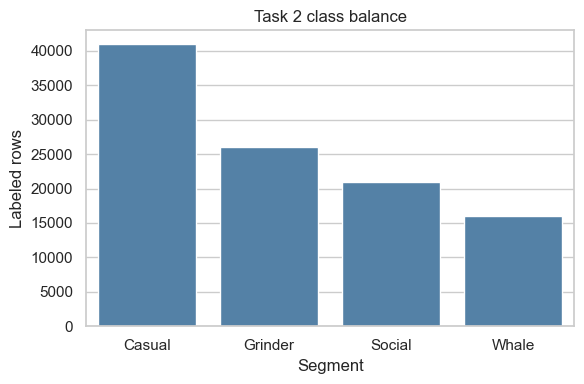

In [3]:
segment_names = {0: "Casual", 1: "Grinder", 2: "Social", 3: "Whale"}
label_counts = train_raw[TARGET].value_counts().sort_index()
display(pd.DataFrame({"segment": [segment_names[x] for x in label_counts.index],
                      "rows": label_counts.values,
                      "percent": (100 * label_counts / len(train_raw)).round(2).values},
                     index=label_counts.index))
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=[segment_names[x] for x in label_counts.index], y=label_counts.values,
            color="steelblue", ax=ax)
ax.set(xlabel="Segment", ylabel="Labeled rows", title="Task 2 class balance")
plt.tight_layout()
plt.show()

## 3. Inspect missingness and feature quality

,train_count,train_pct,test_count,test_pct
payment_method,31892,30.67,8020,30.98
region,27146,26.10,6735,26.01
account_status,8161,7.85,2004,7.74
platform,8113,7.80,2002,7.73
item_type_preference_social,8096,7.78,1976,7.63
item_type_preference_performance,8089,7.78,1972,7.62
random_metric_1,8080,7.77,2025,7.82
skill_tier,8074,7.76,2005,7.74
random_metric_2,8074,7.76,2021,7.81
avg_match_length,8072,7.76,2024,7.82


Fully empty feature rows — train: 0 test: 0
Constant features — train: []


Test-only categorical values: {}


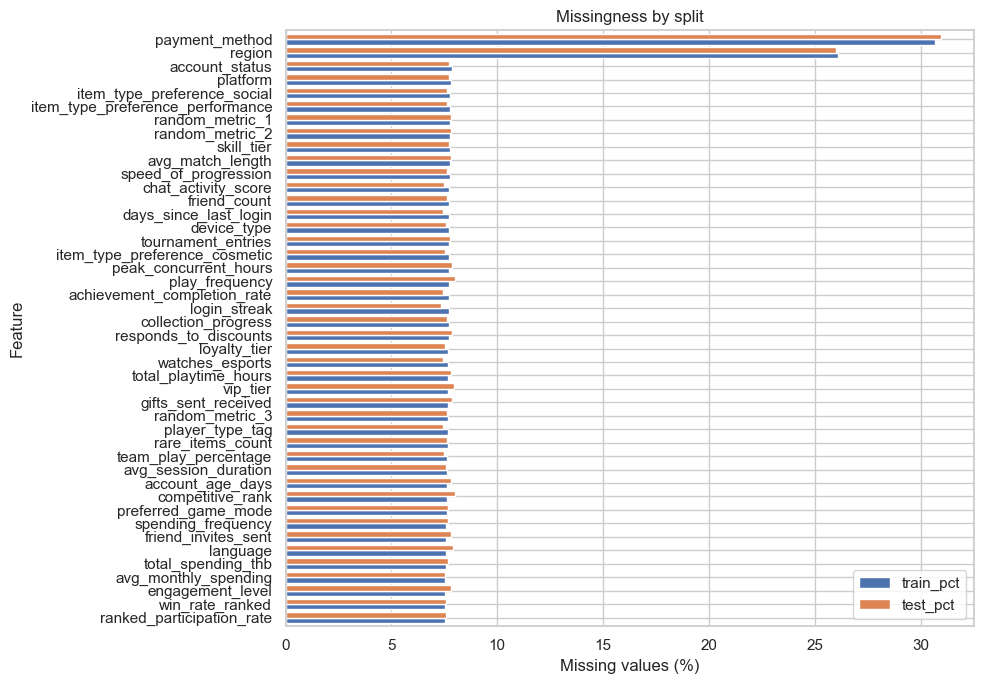

In [4]:
missing = pd.DataFrame({
    "train_count": train_raw[feature_cols].isna().sum(),
    "train_pct": train_raw[feature_cols].isna().mean().mul(100),
    "test_count": test_raw[feature_cols].isna().sum(),
    "test_pct": test_raw[feature_cols].isna().mean().mul(100),
}).sort_values("train_pct", ascending=False)
display(missing.round(2))
print("Fully empty feature rows — train:", train_raw[feature_cols].isna().all(axis=1).sum(),
      "test:", test_raw[feature_cols].isna().all(axis=1).sum())
print("Constant features — train:", [c for c in feature_cols if train_raw[c].nunique(dropna=True) <= 1])
print("Test-only categorical values:",
      {c: sorted(set(test_raw[c].dropna()) - set(train_raw[c].dropna()))
       for c in categorical_cols if set(test_raw[c].dropna()) - set(train_raw[c].dropna())})

fig, ax = plt.subplots(figsize=(10, 7))
missing[["train_pct", "test_pct"]].sort_values("train_pct").plot.barh(ax=ax, width=.8)
ax.set(xlabel="Missing values (%)", ylabel="Feature", title="Missingness by split")
plt.tight_layout()
plt.show()

In [5]:
display(train_raw[numeric_cols].describe(percentiles=[.01, .25, .5, .75, .99]).T.round(3))
display(pd.DataFrame({
    "train_unique": train_raw[categorical_cols].nunique(dropna=True),
    "train_missing_pct": train_raw[categorical_cols].isna().mean().mul(100),
    "test_missing_pct": test_raw[categorical_cols].isna().mean().mul(100),
}).round(2))
display(train_raw.groupby(TARGET)[[
    "play_frequency", "total_spending_thb", "friend_count",
    "ranked_participation_rate", "team_play_percentage",
]].median().rename(index=segment_names).round(2))

,count,mean,std,min,1%,25%,50%,75%,99%,max
play_frequency,95969.0,12.121,7.067,1.000,1.221,6.464,11.420,16.865,30.504,48.700
avg_session_duration,96060.0,107.300,54.250,20.001,21.863,64.032,102.452,143.740,246.651,381.278
total_playtime_hours,95997.0,1700.575,942.451,100.118,135.747,965.468,1635.500,2341.126,4063.774,5992.590
login_streak,95982.0,55.076,35.427,0.000,1.000,26.000,52.000,79.000,147.000,234.000
days_since_last_login,95949.0,45.963,20.925,0.008,2.410,31.238,45.829,60.360,95.149,136.203
total_spending_thb,96126.0,34219.671,22098.076,500.474,1116.724,16335.228,31572.321,49016.415,92423.117,144500.577
avg_monthly_spending,96146.0,3306.262,1935.873,100.052,174.024,1778.197,3163.923,4614.339,8224.741,12960.918
spending_frequency,96092.0,17.030,9.617,1.000,1.377,9.481,16.279,23.570,41.522,64.315
friend_count,95948.0,107.577,64.999,0.000,2.000,56.000,103.000,152.000,272.000,414.000
team_play_percentage,96057.0,50.247,19.725,5.000,5.000,36.656,50.228,63.807,96.669,100.000


,train_unique,train_missing_pct,test_missing_pct
region,4,26.10,26.01
platform,3,7.80,7.73
device_type,4,7.74,7.57
payment_method,3,30.67,30.98
language,6,7.58,7.91
account_status,2,7.85,7.74
player_type_tag,4,7.66,7.45
engagement_level,4,7.53,7.80
loyalty_tier,5,7.70,7.52
skill_tier,5,7.76,7.74


,play_frequency,total_spending_thb,friend_count,ranked_participation_rate,team_play_percentage
segment,,,,,
Casual,9.86,26099.54,87.0,49.37,48.44
Grinder,13.44,28416.71,124.0,51.18,52.10
Social,10.26,37728.88,91.0,49.07,49.10
Whale,13.96,45023.84,127.0,51.30,53.14


## 4. Check possible label proxies

In [6]:
# Inspect only labeled Train. A category that almost determines the target would need review.
proxy_rows = []
for column in categorical_cols:
    tab = pd.crosstab(train_raw[column].fillna("<missing>"), train_raw[TARGET])
    large_groups = tab.loc[tab.sum(axis=1) >= 100]
    proxy_rows.append({
        "feature": column, "categories": len(tab),
        "max_single_class_share": (large_groups.max(axis=1) / large_groups.sum(axis=1)).max(),
    })
proxy_review = pd.DataFrame(proxy_rows).sort_values("max_single_class_share", ascending=False)
display(proxy_review.round(3))
for column in ["player_type_tag", "engagement_level", "loyalty_tier"]:
    print(column)
    display(pd.crosstab(train_raw[column].fillna("<missing>"), train_raw[TARGET],
                        normalize="index").rename(columns=segment_names).round(3))
assert proxy_review.max_single_class_share.max() < .95
print("No categorical value with >=100 rows almost determines a segment.")
print("The raw data has no timestamps proving when inferred tiers were created; keep this availability caveat in the dataset card.")

,feature,categories,max_single_class_share
7,engagement_level,5,0.615
8,loyalty_tier,6,0.601
9,skill_tier,6,0.400
6,player_type_tag,5,0.399
4,language,7,0.399
2,device_type,5,0.397
0,region,5,0.396
3,payment_method,4,0.395
1,platform,4,0.395
5,account_status,3,0.395


player_type_tag


segment,Casual,Grinder,Social,Whale
player_type_tag,,,,
<missing>,0.391,0.254,0.201,0.153
Casual,0.398,0.246,0.201,0.156
Collector,0.391,0.249,0.208,0.152
Competitive,0.399,0.250,0.198,0.153
Social,0.388,0.255,0.201,0.156


engagement_level


segment,Casual,Grinder,Social,Whale
engagement_level,,,,
<missing>,0.390,0.251,0.207,0.152
High,0.185,0.453,0.096,0.267
Low,0.575,0.080,0.291,0.053
Mid,0.393,0.247,0.203,0.157
Veteran,0.008,0.615,0.010,0.367


loyalty_tier


segment,Casual,Grinder,Social,Whale
loyalty_tier,,,,
<missing>,0.396,0.247,0.210,0.148
Bronze,0.601,0.379,0.010,0.010
Diamond,0.010,0.010,0.568,0.412
Gold,0.232,0.155,0.343,0.270
Platinum,0.009,0.009,0.566,0.416
Silver,0.475,0.301,0.124,0.100


No categorical value with >=100 rows almost determines a segment.
The raw data has no timestamps proving when inferred tiers were created; keep this availability caveat in the dataset card.


## 5. Extract row-level behavior features

Ratios expose intensity relative to account age, playtime, purchases, and social contacts. Percentage fields are divided by 100 where needed. The source `play_frequency` exceeds seven in this data, so its stated days/week unit is inconsistent; use it only as a relative activity measure. No label or `player_id` enters a formula.

In [7]:
# Preserve raw columns and missingness. A +1 denominator handles zero values without
# fitting a statistic; missing source values still produce missing engineered values.
def add_behavior_features(df):
    out = df.copy()
    out["session_time_proxy_hours"] = df["play_frequency"] * df["avg_session_duration"] / 60
    out["play_hours_per_account_day"] = df["total_playtime_hours"] / (df["account_age_days"] + 1)
    out["login_recency_over_age"] = df["days_since_last_login"] / (df["account_age_days"] + 1)
    out["spend_per_play_hour"] = df["total_spending_thb"] / (df["total_playtime_hours"] + 1)
    out["spend_per_account_day"] = df["total_spending_thb"] / (df["account_age_days"] + 1)
    out["spend_per_purchase_proxy"] = df["avg_monthly_spending"] / (df["spending_frequency"] + 1)
    out["purchase_to_play_frequency"] = df["spending_frequency"] / (df["play_frequency"] + 1)
    out["social_actions_per_friend"] = (df["friend_invites_sent"] + df["gifts_sent_received"]) / (df["friend_count"] + 1)
    out["team_chat_interaction"] = df["team_play_percentage"] / 100 * df["chat_activity_score"]
    out["social_preference_interaction"] = df["item_type_preference_social"] * df["team_play_percentage"] / 100
    out["ranked_time_proxy_hours"] = out["session_time_proxy_hours"] * df["ranked_participation_rate"] / 100
    out["ranked_win_interaction"] = df["ranked_participation_rate"] / 100 * df["win_rate_ranked"] / 100
    out["cosmetic_vs_performance"] = df["item_type_preference_cosmetic"] - df["item_type_preference_performance"]
    out["source_missing_count"] = df[feature_cols].isna().sum(axis=1)
    return out

train_combined = add_behavior_features(train_raw)
test_combined = add_behavior_features(test_raw)
train_combined[TARGET] = train_combined[TARGET].astype("int8")
engineered_cols = [c for c in test_combined if c not in test_raw]
assert len(engineered_cols) == 14
assert train_combined.drop(columns=TARGET).columns.tolist() == test_combined.columns.tolist()
assert train_combined[feature_cols + [ID]].equals(train_raw[feature_cols + [ID]])
assert test_combined[feature_cols + [ID]].equals(test_raw[feature_cols + [ID]])
assert train_combined[TARGET].equals(train_raw[TARGET].astype("int8"))
assert not np.isinf(train_combined[engineered_cols].to_numpy()).any()
assert not np.isinf(test_combined[engineered_cols].to_numpy()).any()
print("Train/Test rows:", len(train_combined), len(test_combined))
print("Raw/engineered features:", len(feature_cols), len(engineered_cols))
display(pd.DataFrame({
    "train_missing_pct": train_combined[engineered_cols].isna().mean().mul(100),
    "test_missing_pct": test_combined[engineered_cols].isna().mean().mul(100),
}).round(2))
display(train_combined.groupby(TARGET)[engineered_cols].median().rename(index=segment_names).round(3))

Train/Test rows: 104000 25889
Raw/engineered features: 44 14


,train_missing_pct,test_missing_pct
session_time_proxy_hours,14.77,14.93
play_hours_per_account_day,14.71,14.99
login_recency_over_age,14.77,14.64
spend_per_play_hour,14.68,14.88
spend_per_account_day,14.60,14.91
spend_per_purchase_proxy,14.61,14.69
purchase_to_play_frequency,14.77,15.10
social_actions_per_friend,21.28,21.57
team_chat_interaction,14.79,14.42
social_preference_interaction,14.79,14.56


,session_time_proxy_hours,play_hours_per_account_day,login_recency_over_age,spend_per_play_hour,spend_per_account_day,spend_per_purchase_proxy,purchase_to_play_frequency,social_actions_per_friend,team_chat_interaction,social_preference_interaction,ranked_time_proxy_hours,ranked_win_interaction,cosmetic_vs_performance,source_missing_count
segment,,,,,,,,,,,,,,
Casual,12.701,1.785,0.066,19.176,33.915,177.951,1.205,1.253,23.068,0.224,5.203,0.230,-0.006,4.0
Grinder,23.615,2.413,0.046,14.881,36.256,177.723,1.017,1.200,34.921,0.242,9.990,0.260,-0.034,4.0
Social,13.864,1.840,0.062,25.436,47.119,185.416,1.686,1.246,24.365,0.225,5.630,0.232,0.031,4.0
Whale,25.259,2.515,0.045,22.154,55.770,187.695,1.536,1.195,36.900,0.247,10.922,0.263,0.015,4.0


In [8]:
## 6. Save the combined dataset

card_path = SRC / "task2" / "data" / "eda" / f"{DATA_NAME}.json"
if card_path.exists():
    data_info = json.loads(card_path.read_text(encoding="utf-8"))
    assert data_info["name"] == DATA_NAME
    assert data_info["splits"]["train"]["rows"] == len(train_combined)
    assert data_info["splits"]["test"]["rows"] == len(test_combined)
    assert data_info["splits"]["train"]["columns"] == {c: str(t) for c, t in train_combined.dtypes.items()}
    assert data_info["splits"]["test"]["columns"] == {c: str(t) for c, t in test_combined.dtypes.items()}
    assert (SRC / data_info["splits"]["train"]["path"]).exists()
    assert (SRC / data_info["splits"]["test"]["path"]).exists()
    saved_train = pd.read_parquet(SRC / data_info["splits"]["train"]["path"])
    saved_test = pd.read_parquet(SRC / data_info["splits"]["test"]["path"])
    assert saved_train.equals(train_combined) and saved_test.equals(test_combined), "Existing artifact differs; choose a new dataset name"
    print("Loaded existing dataset card:", card_path)
else:
    data_info = save_data(
        task=2, name=DATA_NAME, train=train_combined, test=test_combined,
        card={
            "source": "task2/data/raw/train-outdate-12-11-2026.csv and test-outdate-12-11-2026.csv",
            "parent_dataset": "eda_original_v1",
            "preparation": "All 44 raw features plus 14 deterministic row-level behavior features; no imputation or fitted transforms.",
            "feature_families": "RFM-like recency/spending, play intensity, social interaction, competitive behavior, source missingness",
            "engineered_features": engineered_cols,
            "leakage_review": "No ID or target in formulas; no fitted statistics. Availability time of inferred raw tiers remains undocumented.",
        },
        format="parquet",
    )
    print("Saved dataset:", card_path)
print(data_info["splits"]["train"]["path"])
print(data_info["splits"]["test"]["path"])

Loaded existing dataset card: C:\Users\BTCOM\Desktop\ml-final\src\task2\data\eda\eda_combined_v1.json
task2/data/eda/eda_combined_v1-train.parquet
task2/data/eda/eda_combined_v1-test.parquet


### EDA findings

- Added 14 deterministic numeric features to 44 raw inputs. Raw values and missingness are retained.
- RFM-style spending and recency, play intensity, social participation, and ranked participation are distinct behavioral hypotheses. They require a matched holdout comparison in the model notebook.
- `play_frequency` has values above seven, despite the days/week wording in the datacard. Time-based products using it are relative activity proxies, not literal weekly hours.
- `engagement_level` and `loyalty_tier` remain possible temporal availability risks. Validate their creation time before deployment.